# 03 — MLP de regressão: protocolo e baseline

**Objetivo:** montar a primeira rede neural do problema de regressão (`Burnout_Score`), usando exatamente o mesmo dataset, as mesmas features e a mesma divisão treino/teste da atividade anterior. Aqui definimos o **baseline** e o protocolo; o conjunto de teste **não é consultado** — fica reservado para a avaliação final (notebook 07).

## Decisões do protocolo

- Alvo contínuo `Burnout_Score` (0–100): saída linear com 1 neurônio e `nn.MSELoss`.
- O alvo também é padronizado com média/desvio do **treino**; as métricas abaixo são reconvertidas para a escala original.
- Features padronizadas com `StandardScaler` ajustado **apenas no treino**.
- Split salvo em `data/processed/splits/`: 32.000 treino / 8.000 validação / 10.000 teste, semente 42 (o teste é idêntico ao da atividade 2).
- Baseline: 2 camadas ocultas (32, 32), ReLU, sem dropout, Adam com η=1e−3, batch 128, até 200 épocas com paciência 20.
- `torch.set_num_threads(2)`: no benchmark desta máquina, 2 threads foram mais rápidas que o default (4).
- Batch 128 em vez de 32: o benchmark mediu ~1,7 s/época contra ~4,4 s/época. O efeito do tamanho do batch será estudado separadamente na notebook 05.

In [1]:
import json
import sys

sys.path.append('..')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

from src.config import (REGRESSION_DATASET, REGRESSION_TARGET, SEED,
                        FIGURES_DIR, TABLES_DIR, REPORTS_DIR)
from src.models import MLP
from src.split import carregar_split
from src.train import set_seed, criar_loader, treinar_modelo

torch.set_num_threads(2)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR = REPORTS_DIR / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print('PyTorch:', torch.__version__, '| threads:', torch.get_num_threads(), '| semente:', SEED)

Matplotlib is building the font cache; this may take a moment.


PyTorch: 2.15.0+cpu | threads: 2 | semente: 42


## 1. Carregamento, split e padronização

A ordem das features é preservada em `FEATURES` — ela vai para o checkpoint e será reutilizada na inferência.

In [2]:
df = pd.read_csv(REGRESSION_DATASET)
FEATURES = [c for c in df.columns if c != REGRESSION_TARGET]
split = carregar_split('regressao')

X = df[FEATURES].to_numpy(dtype=np.float32)
y = df[REGRESSION_TARGET].to_numpy(dtype=np.float32)

x_scaler = StandardScaler().fit(X[split.train])
X_padronizado = x_scaler.transform(X).astype(np.float32)

y_scaler = StandardScaler().fit(y[split.train].reshape(-1, 1))
y_padronizado = y_scaler.transform(y.reshape(-1, 1)).astype(np.float32).ravel()

print(f'{len(FEATURES)} features | treino={len(split.train)}, validacao={len(split.val)}, teste={len(split.test)}')
print('media/desvio do alvo no treino:', float(y_scaler.mean_[0]), float(y_scaler.scale_[0]))

85 features | treino=32000, validacao=8000, teste=10000
media/desvio do alvo no treino: 40.2508125 26.202784309875234


## 2. Métrica na escala original e configuração baseline

A rede é treinada com o alvo padronizado, mas `rmse_original()` inverte a transformação antes de comparar. Assim o número é comparável com os resultados da atividade anterior.

In [3]:
def rmse_original(y_true_padrao, y_pred_padrao):
    y_true = y_scaler.inverse_transform(np.asarray(y_true_padrao).reshape(-1, 1)).ravel()
    y_pred = y_scaler.inverse_transform(np.asarray(y_pred_padrao).reshape(-1, 1)).ravel()
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

gen = set_seed(SEED)
dl_treino = criar_loader(X_padronizado[split.train], y_padronizado[split.train],
                         batch_size=128, shuffle=True, tarefa='regressao', generator=gen)
dl_val = criar_loader(X_padronizado[split.val], y_padronizado[split.val],
                      batch_size=256, shuffle=False, tarefa='regressao')

config = dict(in_dim=len(FEATURES), out_dim=1, hidden=(32, 32),
              activation='ReLU', dropout=0.0)
modelo = MLP(**config)
otimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)
perda = torch.nn.MSELoss()

resultado = treinar_modelo(modelo, dl_treino, dl_val, perda, otimizador,
                           n_epocas=200, paciencia=20, device='cpu',
                           metric_fn=rmse_original)

print(f'epoca parada={resultado.stop_epoch} | melhor epoca={resultado.best_epoch}')
print(f'tempo={resultado.duration_s:.1f}s | parametros={modelo.n_parametros}')
print('RMSE original treino=%.4f | validacao=%.4f' % (resultado.metricas_finais['treino'], resultado.metricas_finais['validacao']))

epoca parada=27 | melhor epoca=7
tempo=68.8s | parametros=3841
RMSE original treino=8.6664 | validacao=9.1390


## 3. Curvas de aprendizado

A linha tracejada marca a época de menor perda na validação — o ponto restaurado pelo early stopping.

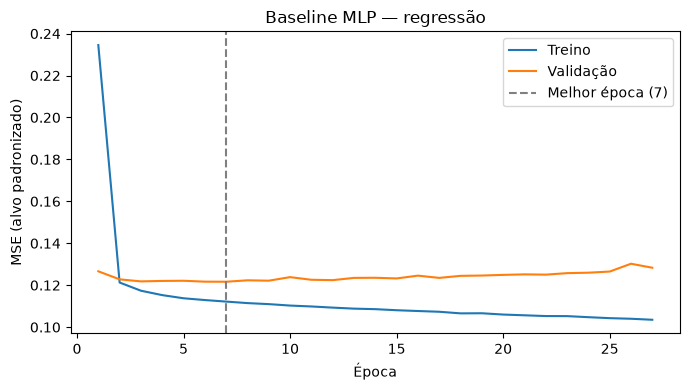

In [4]:
epocas = np.arange(1, len(resultado.history['treino_loss']) + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epocas, resultado.history['treino_loss'], label='Treino')
ax.plot(epocas, resultado.history['val_loss'], label='Validação')
ax.axvline(resultado.best_epoch, color='grey', linestyle='--',
           label=f'Melhor época ({resultado.best_epoch})')
ax.set(xlabel='Época', ylabel='MSE (alvo padronizado)', title='Baseline MLP — regressão')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / '03_mlp_regressao_perda.png', dpi=200)
plt.show()

## 4. Artefatos do baseline

O histórico e os metadados (inclusive as médias/desvios do `StandardScaler`) são salvos agora para que as próximas notebooks reutilizem exatamente o mesmo protocolo. O checkpoint `.pt` completo será gravado na notebook 06.

In [5]:
historico = pd.DataFrame({
    'epoca': epocas,
    'mse_treino': resultado.history['treino_loss'],
    'mse_validacao': resultado.history['val_loss'],
})
historico.to_csv(TABLES_DIR / '03_mlp_regressao_historico.csv', index=False)

metadados = {
    'problema': 'regressao',
    'alvo': REGRESSION_TARGET,
    'features': FEATURES,
    'configuracao': modelo.configuracao(),
    'semente': SEED,
    'batch_size': 128,
    'otimizador': 'Adam',
    'learning_rate': 1e-3,
    'perda': 'MSELoss',
    'epoca_parada': resultado.stop_epoch,
    'melhor_epoca': resultado.best_epoch,
    'tempo_treino_s': resultado.duration_s,
    'parametros': modelo.n_parametros,
    'rmse_original_treino': resultado.metricas_finais['treino'],
    'rmse_original_validacao': resultado.metricas_finais['validacao'],
    'x_media': x_scaler.mean_.tolist(),
    'x_desvio': x_scaler.scale_.tolist(),
    'y_media': y_scaler.mean_.tolist(),
    'y_desvio': y_scaler.scale_.tolist(),
}
(MODELS_DIR / '03_baseline_regressao.json').write_text(
    json.dumps(metadados, indent=2, ensure_ascii=False), encoding='utf-8')
print('Salvo:', TABLES_DIR / '03_mlp_regressao_historico.csv')
print('Salvo:', MODELS_DIR / '03_baseline_regressao.json')

Salvo: C:\Users\jose2\OneDrive\Documentos\DCT1401-Inteligencia-Artificial\reports\tables\03_mlp_regressao_historico.csv
Salvo: C:\Users\jose2\OneDrive\Documentos\DCT1401-Inteligencia-Artificial\reports\models\03_baseline_regressao.json


## Próximos passos

1. `04_mlp_classificacao.ipynb` — baseline análogo com `CrossEntropyLoss` (3 classes).
2. `05_hiperparametros.ipynb` — estudo de um fator por vez, mapa de calor e random search, sempre na validação.
3. `06_salvar_carregar_inferencia.ipynb` — checkpoints `.pt` e script `src/inference.py`.
4. `07/08` — métricas no teste (uma única vez) e eficiência computacional.